In [ ]:
import deep_models.config as c
from deep_models.data import load_folds, make_splits, S00MILDataset
from torch.utils.data import DataLoader
from deep_models.vqvae import ConvVQVAE
from deep_models.vqvae_train import encode_bags, plot_reconstructions, plot_tsne, plot_prior_samples

In [ ]:
split_k = 2
num_workers = 4

In [ ]:
developamental_folds = load_folds(c.dev_path)
_, train_idx, val_idx, test_idx = next(split for split in make_splits(developamental_folds) if split[0] == split_k)
print(f"train={len(train_idx)}  val={len(val_idx)}  test={len(test_idx)}")

train=1078  val=129  test=146


In [ ]:
train_ds = S00MILDataset(train_idx, max_instances=150, train=True)
val_ds   = S00MILDataset(val_idx,   max_instances=150, train=False)

train_loader = DataLoader(train_ds, batch_size=10, shuffle=True,  num_workers=num_workers, pin_memory=True)
val_loader   = DataLoader(val_ds,   batch_size=10, shuffle=False, num_workers=num_workers, pin_memory=True)

In [ ]:
model = ConvVQVAE(latent_channels=16,
                  code_book_size=64,
                  commitment_cost=0.25,
                  init_channels=16).to(c.device) 

state_dict = torch.load(f"best_vqvae_split{split_k}.pt", map_location=c.device, weights_only=True)
model.load_state_dict(state_dict)
model.eval()

ConvVQVAE(
  (encoder): VQEncoder(
    (conv_1): Conv2d(5, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (conv_block1): DownBlock(
      (bn1): GroupNorm(8, 16, eps=1e-05, affine=True)
      (conv1): Conv2d(16, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
      (bn2): GroupNorm(8, 32, eps=1e-05, affine=True)
      (conv2): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (conv3): Conv2d(16, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    )
    (conv_block2): DownBlock(
      (bn1): GroupNorm(8, 32, eps=1e-05, affine=True)
      (conv1): Conv2d(32, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
      (bn2): GroupNorm(8, 64, eps=1e-05, affine=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (conv3): Conv2d(32, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    )
    (res_block_1): ResBlock(
      (norm1): GroupNorm(8, 64, eps=1e-05, affine=True)
      (conv1): Conv2d(64, 6

In [ ]:
z_q_val, idx_val, y_val = encode_bags(model, val_loader)

active codes: 28/64   perplexity: 24.5/64


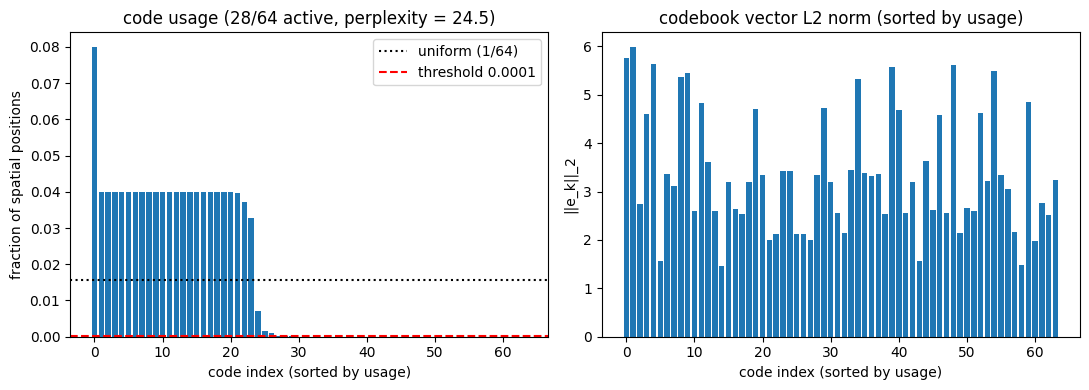

In [8]:
fig_codes, order, n_active = plot_codebook_usage(model, idx_val)

# See how well it reconstructs

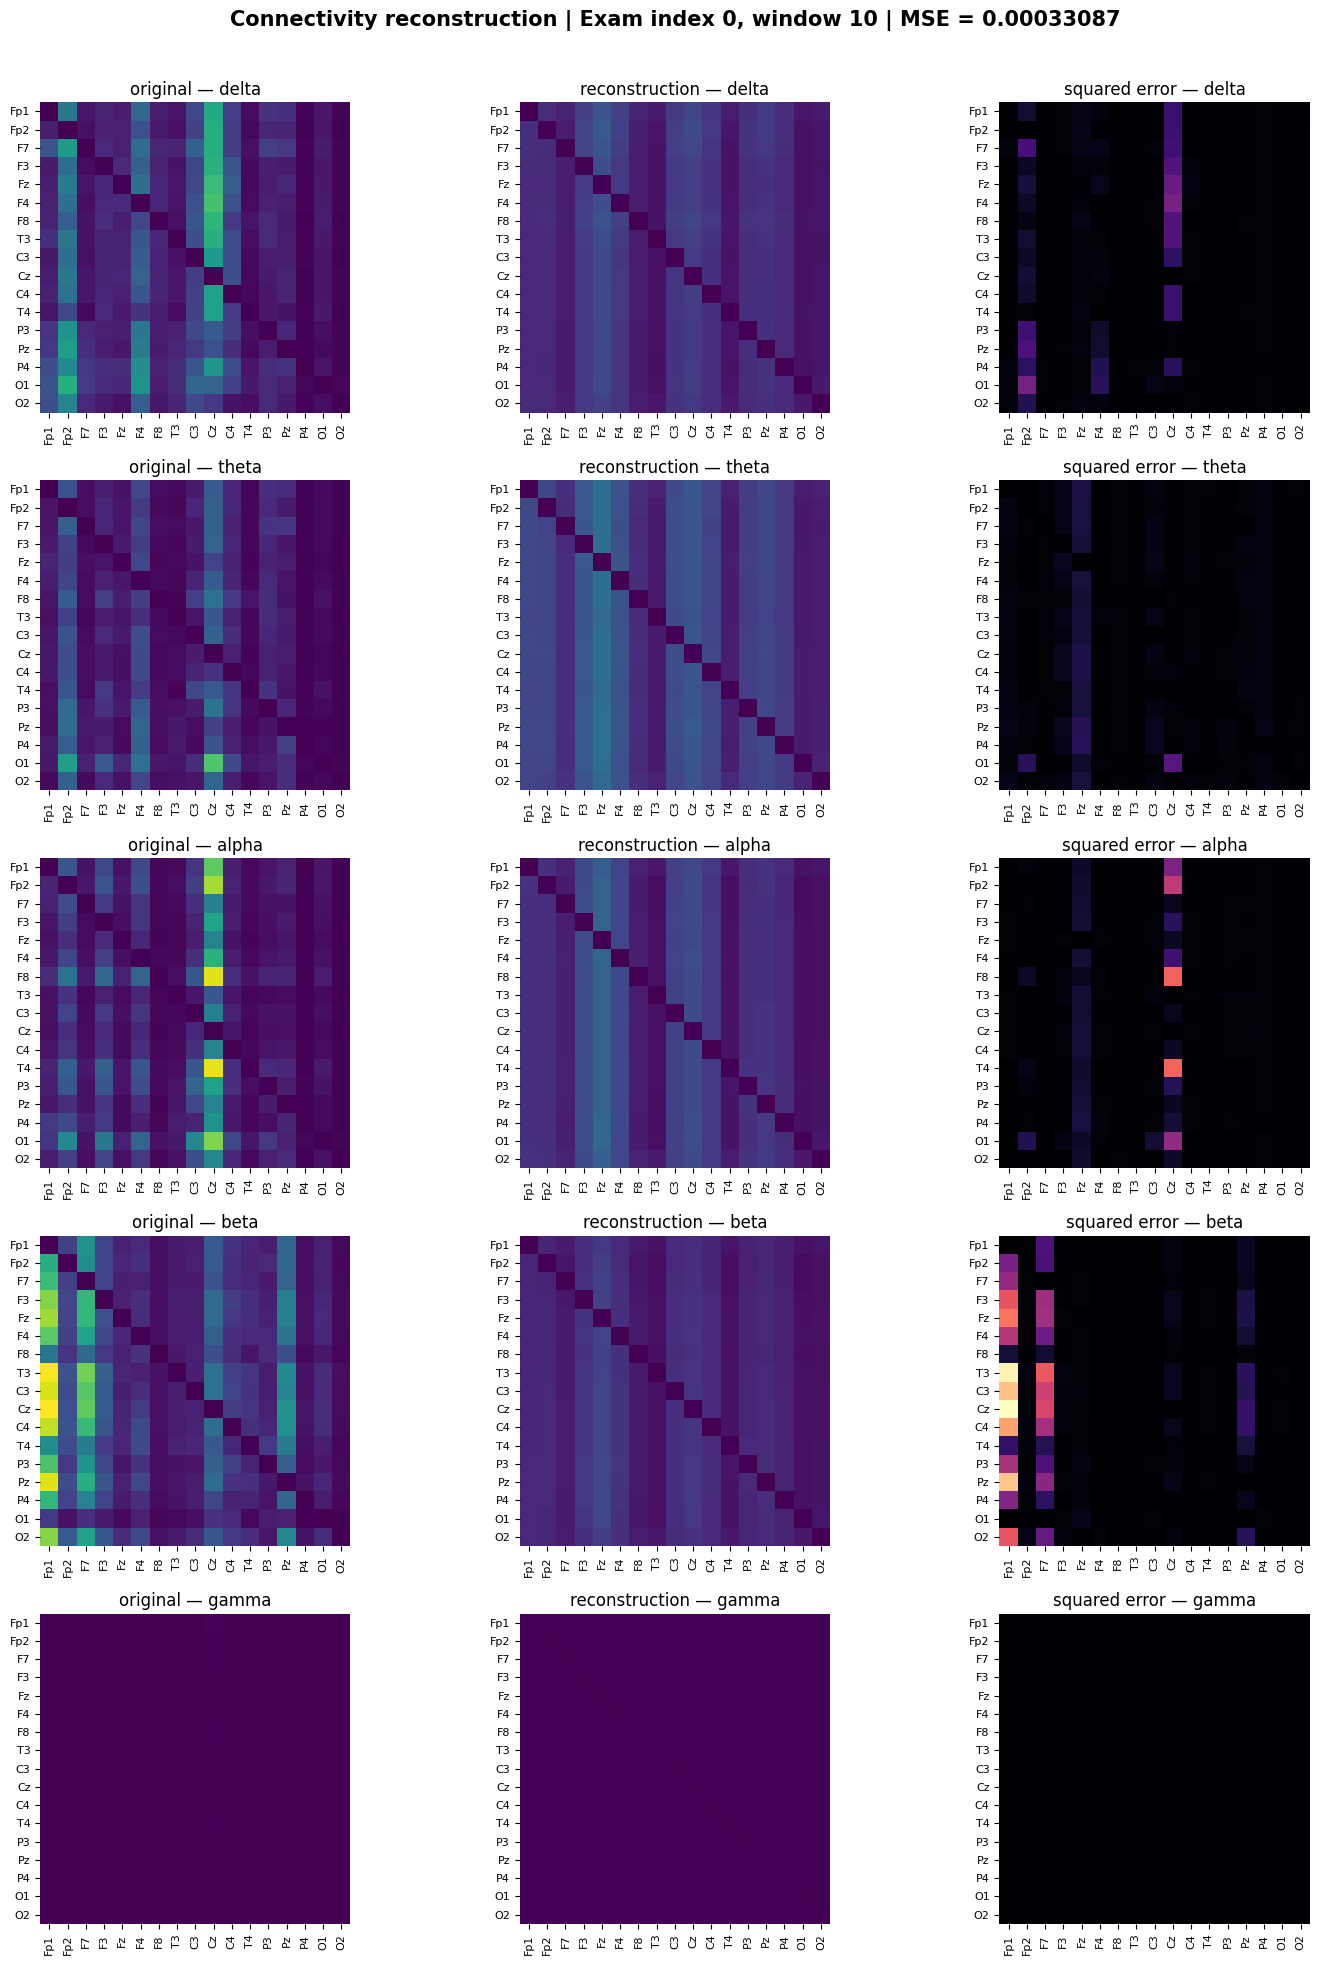

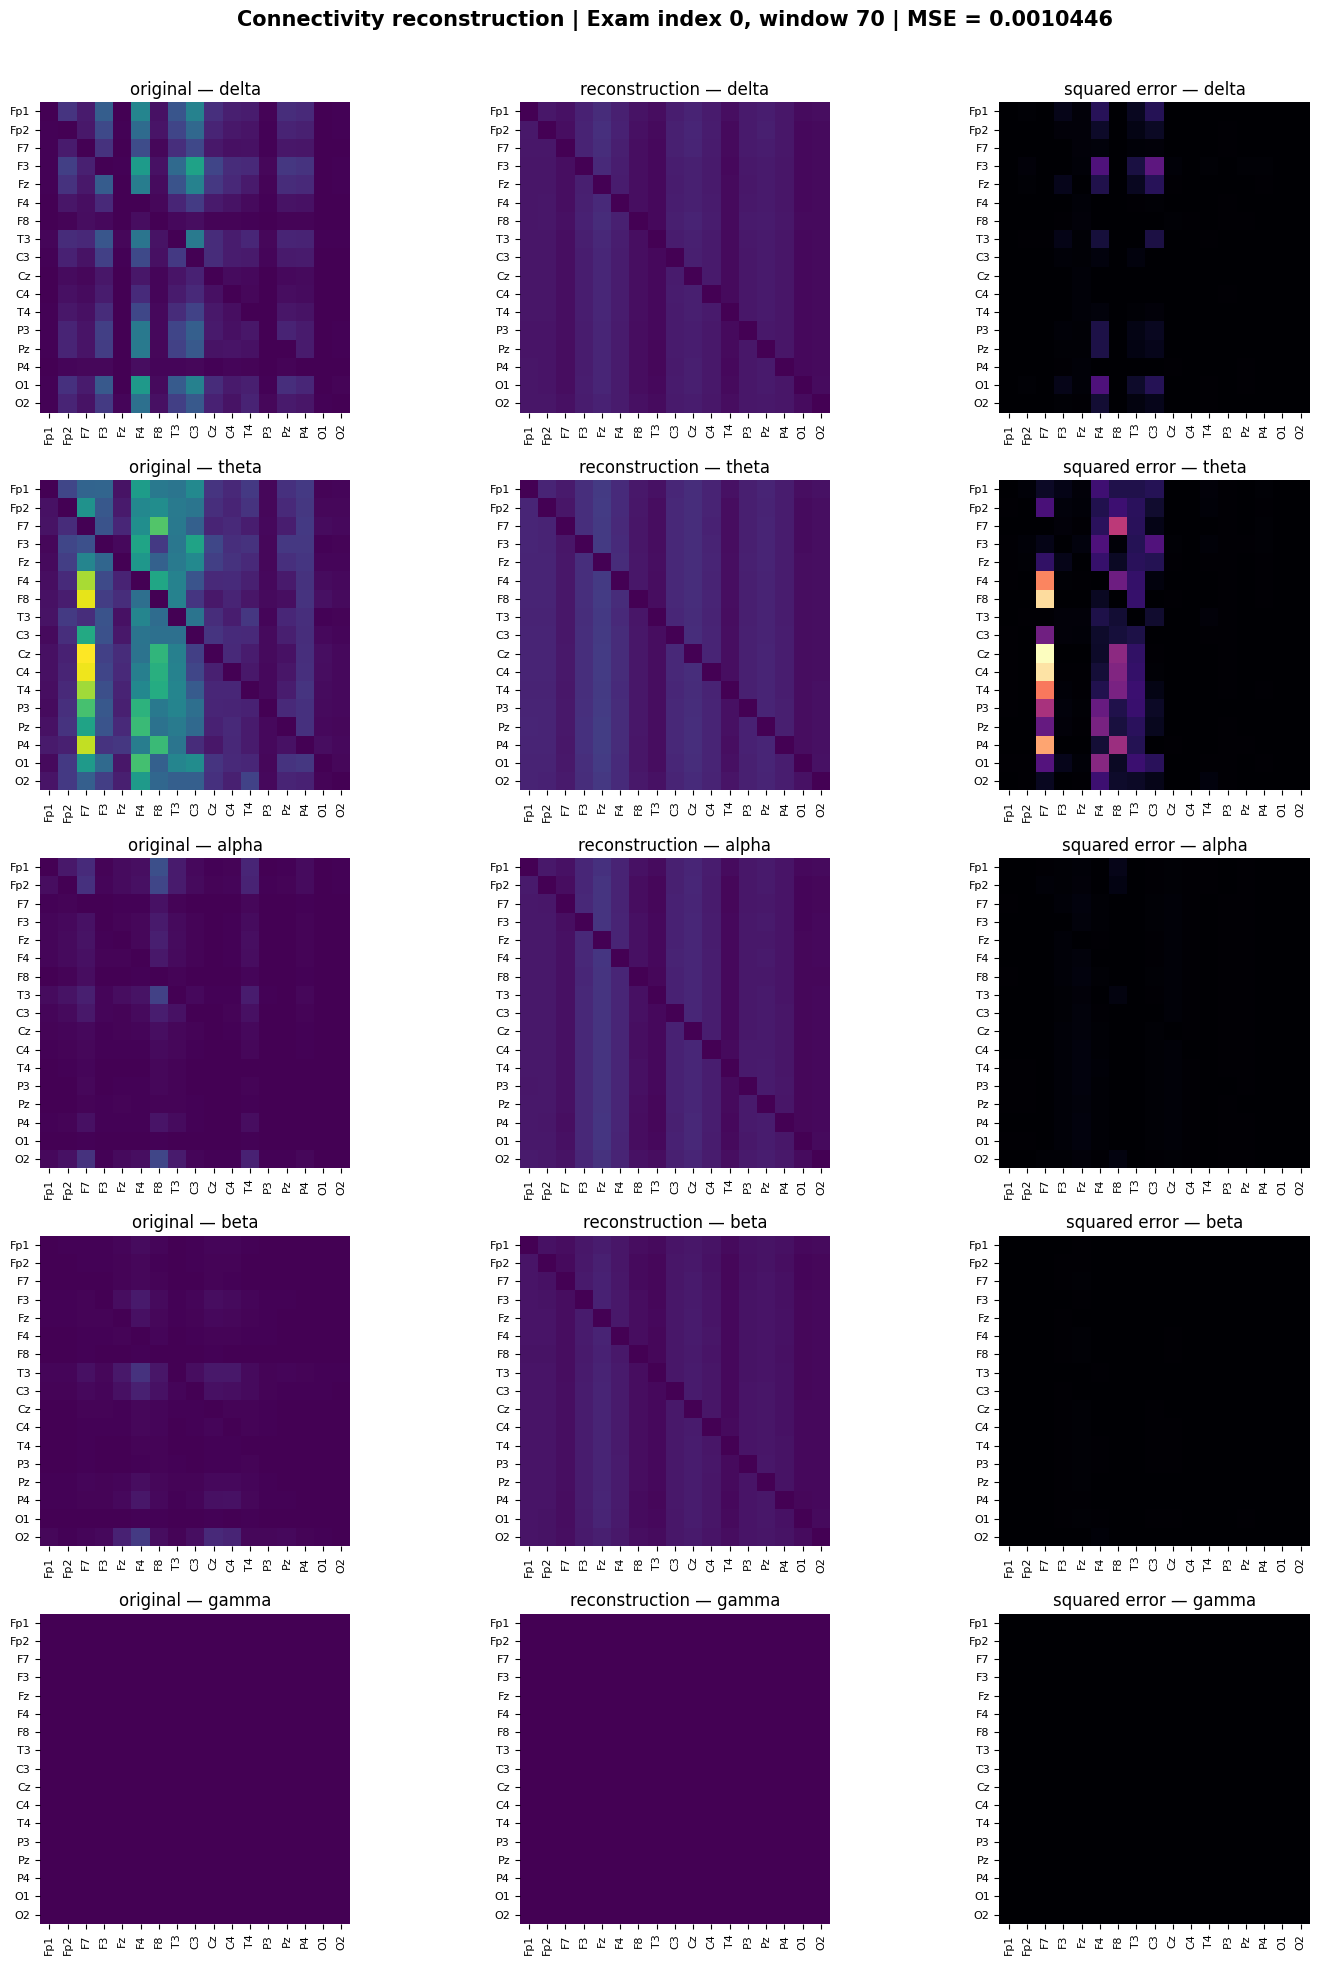

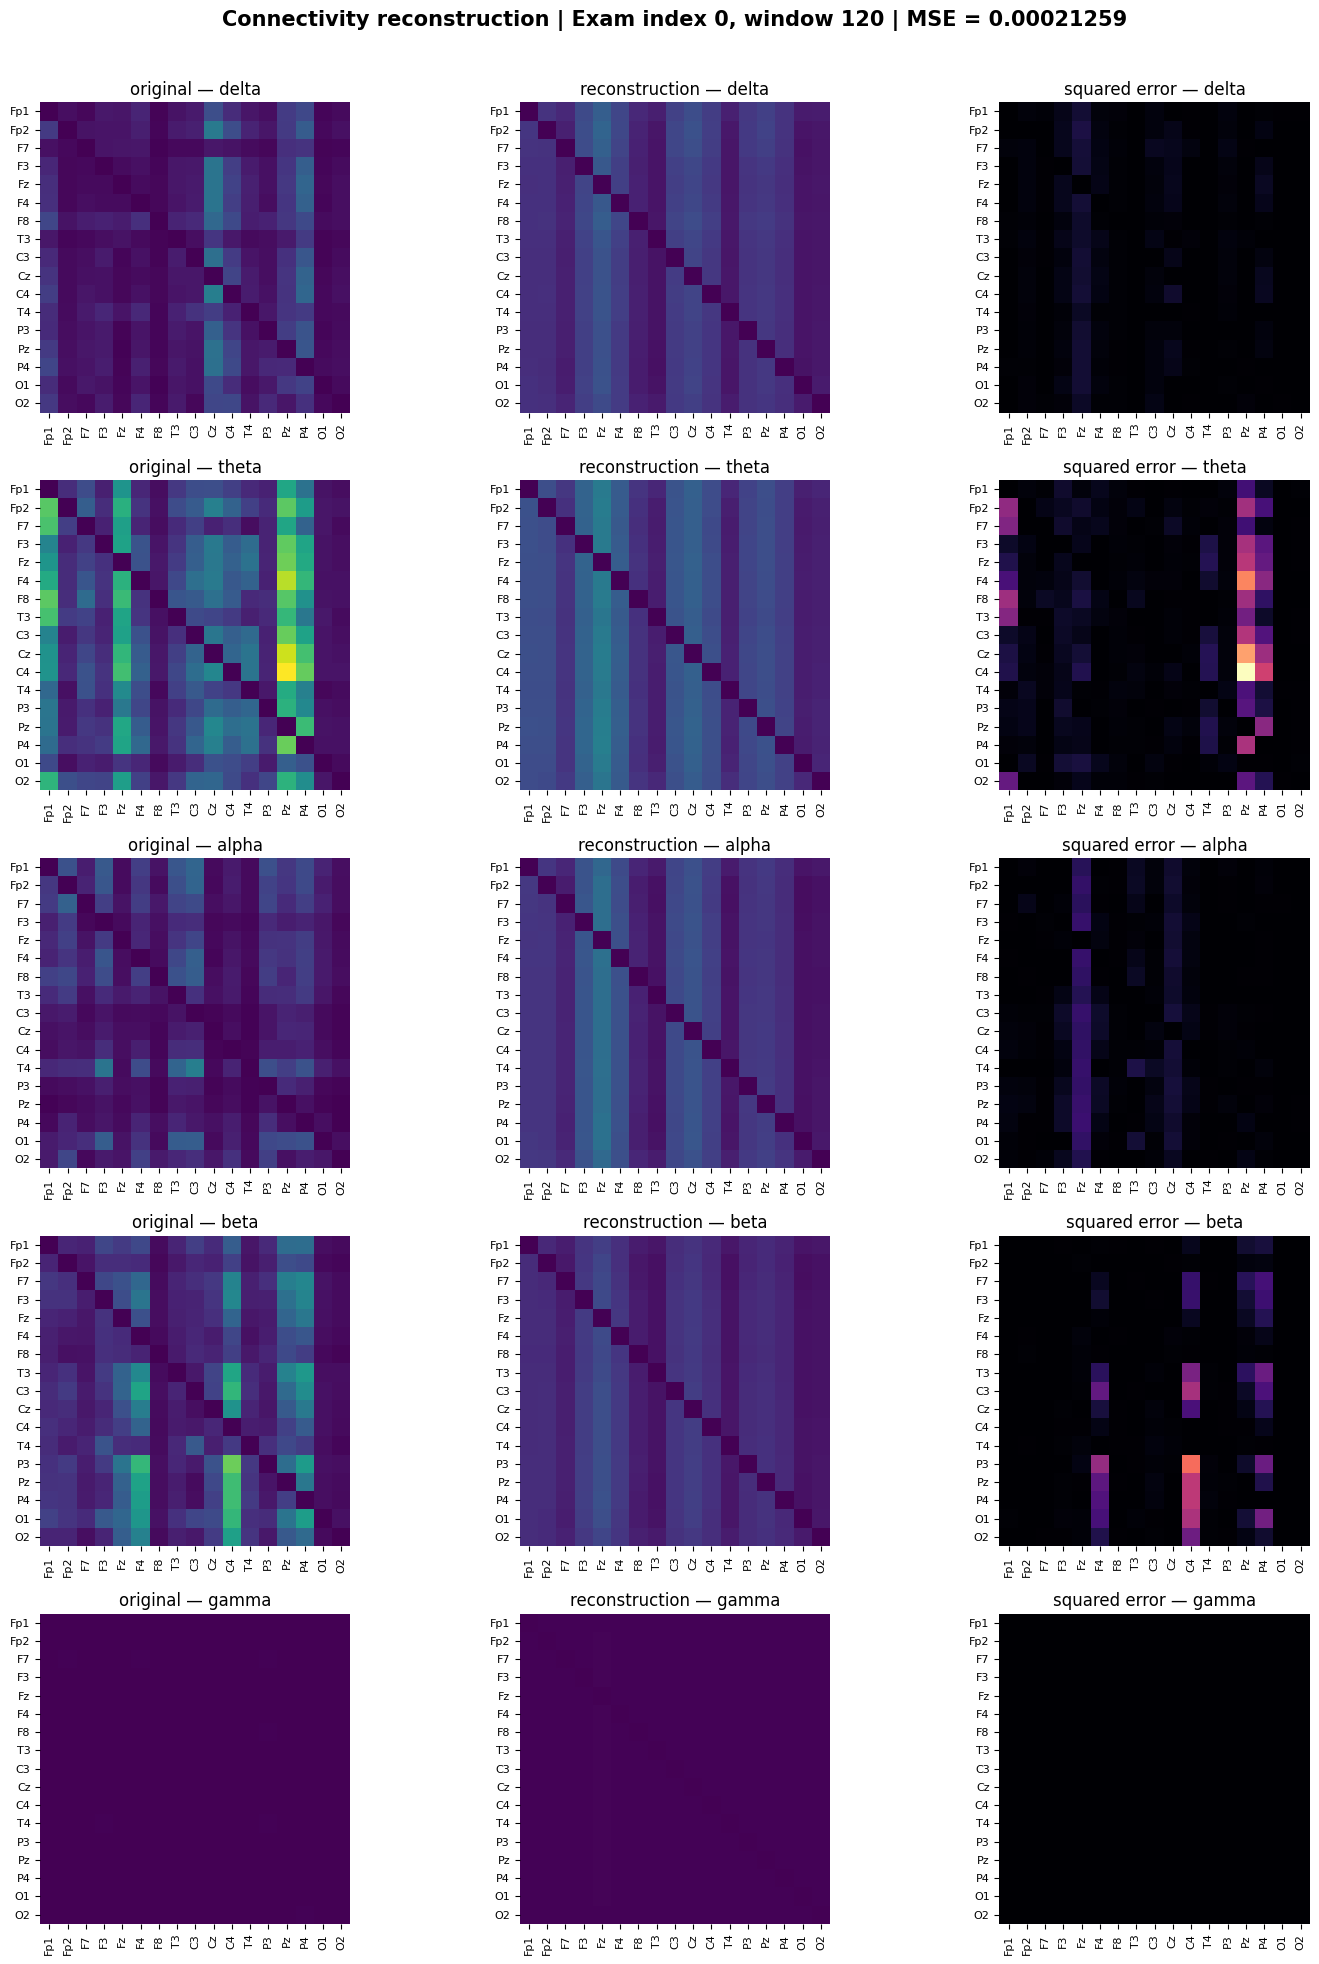

In [ ]:
plot_reconstructions(model, val_loader, exam_idx=5, window_indices=(10, 70, 120))

# How does the latent space look?

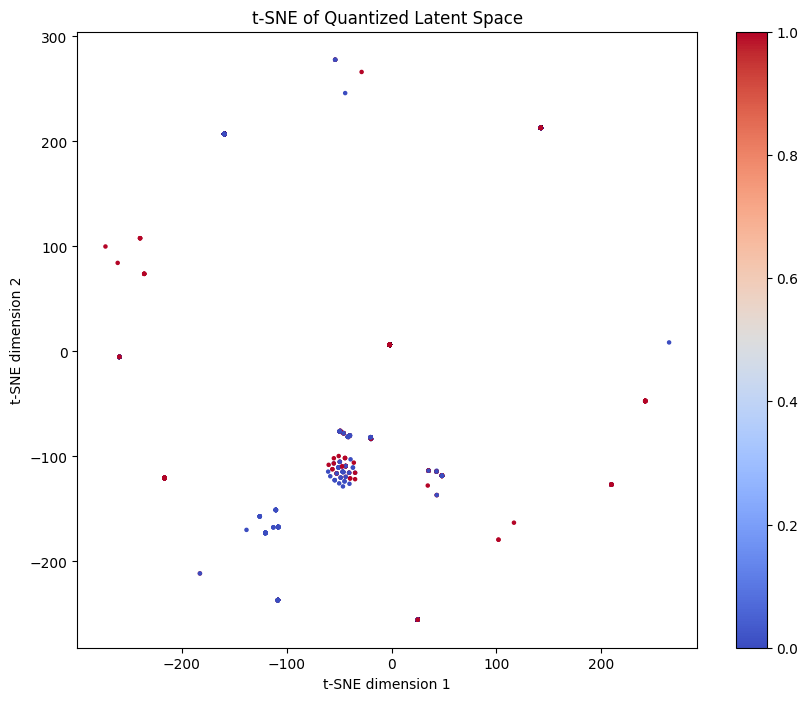

In [11]:
g = plot_tsne(z_q_val, y_val)
g.show()

# Test out the generative skill

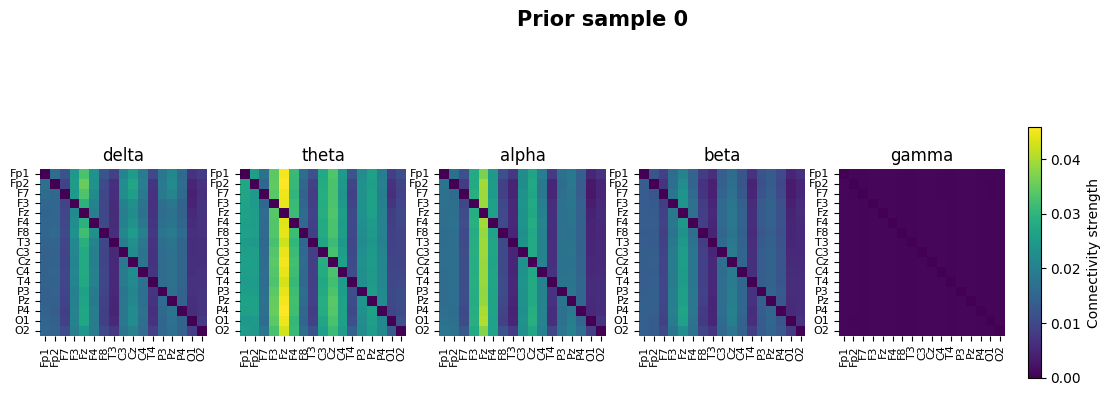

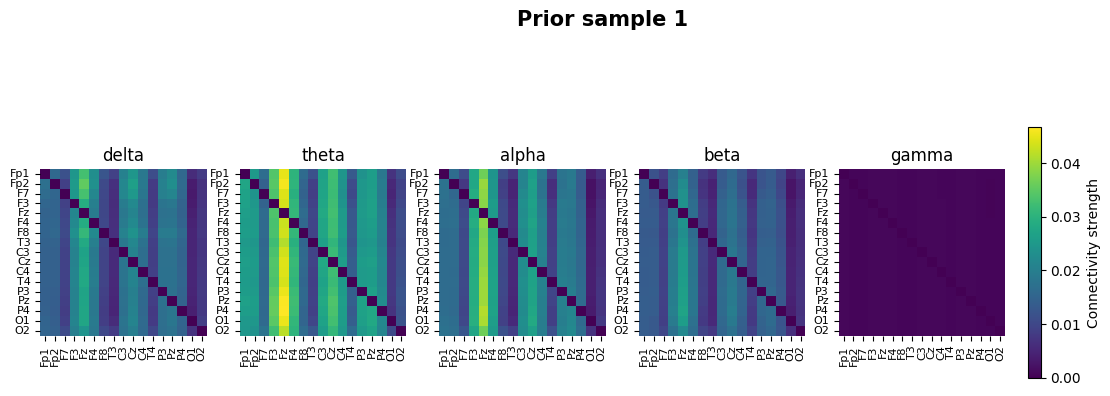

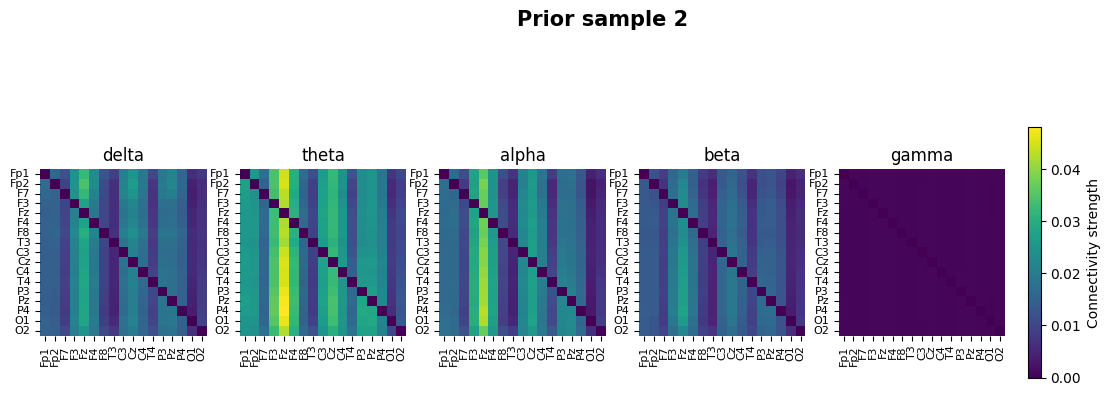

In [ ]:
plot_prior_samples(model, num_samples=3)